[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_16/MFM_ch16_defi/MFM_ch16_defi.ipynb)

# MFM_ch16_defi

Decentralised finance: total value locked across all chains and the Ether price (monthly regression with Newey-West errors), and total value locked by blockchain (DefiLlama).

*Modelling Financial Markets (MFM), Chapter 16: Digital Assets and DeFi. Author: Daniel Traian Pele.*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_16'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261021T110651-8a3769


In [ ]:
import os
import json
import time
import urllib.request
import urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.signal import lfilter
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours (no grey: navy reference lines, light-blue bands)
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Teal     = '#17A2B8'
Magenta  = '#D63384'
Brown    = '#795548'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
COL = {'BTC': Orange, 'ETH': Purple, 'XRP': MainBlue, 'ADA': Forest, 'DOGE': Amber, 'LTC': Teal, 'LINK': IDAred,
       'SOL': Magenta, 'BNB': Brown, 'SPX': MainBlue, 'GOLD': Amber, 'QQQ': Teal, 'USDT': Forest, 'USDC': MainBlue,
       'DAI': Orange, 'IBIT': MainBlue, 'ETHA': Purple, 'COIN': MainBlue, 'MSTR': IDAred, 'TLT': Forest}
CLASS_COL = {'Crypto': Orange, 'Equity': MainBlue, 'FX': Forest, 'Commodity': Amber, 'Bond': Purple}

HERE = '.'
SEED = 42
ETF_START = '2024-01-11'
B_BOOT = 2000


def save_fig(name):
    """Save the figure as a transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """A single legend below a multi-panel figure."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels and not l.startswith('_'):
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def jsonable(x):
    """Recursively convert numpy numbers and dates to JSON types."""
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (pd.Timestamp,)):
        return str(x.date())
    return x


def max_drawdown(p):
    """Largest fall from a previous peak (in %) and the date of the trough."""
    dd = p / p.cummax() - 1
    return 100 * dd.min(), dd.idxmin()


def hill(x, frac=0.05):
    """Hill estimator of the tail index from the largest frac of the positive values of x."""
    x = np.sort(x[x > 0])[::-1]
    k = max(int(frac * len(x)), 10)
    return 1 / np.mean(np.log(x[:k] / x[k]))


def hac_ols(y, X, lags=4):
    """OLS regression with Newey-West (HAC) standard errors."""
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})

## Data

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# read the course data
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# key -> (symbol, label, type, Coin Metrics id)
ASSETS = {
    'BTC': ('BTC-USD.CC', 'Bitcoin', 'crypto', 'btc'),
    'ETH': ('ETH-USD.CC', 'Ethereum', 'crypto', 'eth'),
    'XRP': ('XRP-USD.CC', 'XRP', 'crypto', 'xrp'),
    'BNB': ('BNB-USD.CC', 'BNB', 'crypto', None),
    'SOL': ('SOL-USD.CC', 'Solana', 'crypto', None),
    'ADA': ('ADA-USD.CC', 'Cardano', 'crypto', 'ada'),
    'DOGE': ('DOGE-USD.CC', 'Dogecoin', 'crypto', 'doge'),
    'LTC': ('LTC-USD.CC', 'Litecoin', 'crypto', 'ltc'),
    'LINK': ('LINK-USD.CC', 'Chainlink', 'crypto', 'link'),
    'USDT': ('USDT-USD.CC', 'Tether (USDT)', 'crypto', None),
    'USDC': ('USDC-USD.CC', 'USD Coin (USDC)', 'crypto', None),
    'DAI': ('DAI-USD.CC', 'Dai', 'crypto', None),
    'IBIT': ('IBIT.US', 'IBIT (spot Bitcoin ETF)', 'etf', None),
    'ETHA': ('ETHA.US', 'ETHA (spot Ether ETF)', 'etf', None),
    'COIN': ('COIN.US', 'Coinbase', 'etf', None),
    'MSTR': ('MSTR.US', 'Strategy', 'etf', None),
    'QQQ': ('QQQ.US', 'Nasdaq 100 (QQQ)', 'etf', None),
    'GLD': ('GLD.US', 'Gold (GLD)', 'etf', None),
    'TLT': ('TLT.US', 'Long Treasuries (TLT)', 'etf', None),
    'SPX': ('GSPC.INDX', 'S&P 500', 'index', None),
    'GOLD': ('XAUUSD.FOREX', 'Gold (XAU/USD)', 'fx', None),
}
LABELS = {k: v[1] for k, v in ASSETS.items()}
# assets with a price series whose public current supply equals the circulating supply
# (XRP and Chainlink: the reported supply includes tokens held by the issuer; Solana, BNB: no public supply)
CRIX_UNIVERSE = ['BTC', 'ETH', 'DOGE', 'ADA', 'LTC']
STABLE = ['USDT', 'USDC', 'DAI']

_CACHE = {}
UA = {'User-Agent': 'Mozilla/5.0 (MFM course notebook)'}


def _get_json(url, tries=4):
    """Read a JSON response."""
    if url == 'https://api.llama.fi/v2/chains' or url.startswith('https://api.llama.fi/v2/historicalChainTvl'):
        import gzip, hashlib
        snapshot_sha = '11d0bbfc3695f65c286f12d4dd97109eafac97e6e6551ddf0fdcf43197b48cf9'
        snapshot_name = 'defi16-20261016-11d0bbfc3695f65c.json.gz'
        cache_key = ('defi_snapshot', snapshot_sha)
        if cache_key not in _CACHE:
            local = os.path.join(os.path.dirname(MARKET_DIR), 'snapshots', snapshot_name)
            if os.path.isfile(local):
                with open(local, 'rb') as handle:
                    raw = handle.read()
            else:
                snapshot_url = 'https://raw.githubusercontent.com/danpele/MFM/main/data/snapshots/' + snapshot_name
                with urllib.request.urlopen(snapshot_url, timeout=120) as response:
                    raw = response.read()
            if hashlib.sha256(raw).hexdigest() != snapshot_sha:
                raise ValueError('DeFi snapshot SHA256 mismatch; refusing different data.')
            _CACHE[cache_key] = json.loads(gzip.decompress(raw))
            print('DeFi snapshot: extracted 2026-10-16 UTC; SHA256 ' + snapshot_sha)
            print('Candidates: current top15 chains at extraction; report top10 using last historical observation <= END=' + END + '.')
            print('Current candidate universe is not the full END-date universe. Endpoint timestamps differ; this is not an atomic snapshot or a claim of identity to earlier runs.')
        payloads = _CACHE[cache_key]['payloads']
        if url not in payloads:
            raise KeyError('Endpoint absent from frozen DeFi course snapshot: ' + url)
        return payloads[url]
    if url.startswith('https://stablecoins.llama.fi/'):
        import gzip, hashlib
        snapshot_sha = '979c073f257838890203b31fc46d3f074b750c3b51978cd4f4432d4ef2cf6528'
        snapshot_name = 'stablecoin16-20261021-979c073f25783889.json.gz'
        cache_key = ('stablecoin_snapshot', snapshot_sha)
        if cache_key not in _CACHE:
            local = os.path.join(os.path.dirname(MARKET_DIR), 'snapshots', snapshot_name)
            if os.path.isfile(local):
                with open(local, 'rb') as handle:
                    raw = handle.read()
            else:
                snapshot_url = 'https://raw.githubusercontent.com/danpele/MFM/main/data/snapshots/' + snapshot_name
                with urllib.request.urlopen(snapshot_url, timeout=120) as response:
                    raw = response.read()
            if hashlib.sha256(raw).hexdigest() != snapshot_sha:
                raise ValueError('Stablecoin snapshot SHA256 mismatch; refusing to use different data.')
            _CACHE[cache_key] = json.loads(gzip.decompress(raw))
            print('Stablecoin snapshot: extracted 2026-10-21 UTC; SHA256 ' + snapshot_sha)
            print('Universe and peg mechanism: current metadata at extraction; select current supply >= USD 100m. Values: last observation <= END=' + END + ', at most 3 days old.')
            print('This is not the complete END-date universe. Missing/stale values are omitted, not economic zeros; endpoints were fetched at different times.')
        if url == 'https://stablecoins.llama.fi/stablecoins?includePrices=false':
            key = 'list'
        elif url == 'https://stablecoins.llama.fi/stablecoincharts/all':
            key = 'all'
        elif url.startswith('https://stablecoins.llama.fi/stablecoincharts/all?stablecoin=') and url.split('stablecoin=')[1].isdigit():
            key = 'id_' + url.split('stablecoin=')[1]
        else:
            raise KeyError('Unsupported frozen stablecoin endpoint: ' + url)
        payloads = _CACHE[cache_key]['payloads']
        if key not in payloads:
            raise KeyError('Stablecoin id absent from this frozen course snapshot: ' + key)
        return payloads[key]
    for i in range(tries):
        try:
            return json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=120))
        except Exception:
            if i == tries - 1:
                raise
            time.sleep(3 * (i + 1))


def read_market(symbol):
    """Read the daily price series of one asset from the course data."""
    if symbol in _CACHE:
        return _CACHE[symbol]
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    _CACHE[symbol] = pd.read_csv(src, index_col='date', parse_dates=True).sort_index()
    return _CACHE[symbol]


def artificial_fill(d):
    """Rows that repeat the previous close and show no trading: an artificial non-trading-day fill.

    A repeated close is a fill only if the row itself shows no trading: zero volume (for files that report
    volume), no intraday range (open = high = low = close) or a copy of the previous row in every field. A
    repeated close on a day with volume and an intraday range is a genuine unchanged close (a zero return)
    and is kept. Files with closes only (the BET) give no such evidence, so every row is kept.
    """
    repeat = d['close'].diff() == 0
    no_trade = pd.Series(False, index=d.index)
    if 'volume' in d and (d['volume'] > 0).mean() > 0.5:
        no_trade |= d['volume'].fillna(0) <= 0
    if {'open', 'high', 'low'} <= set(d.columns):
        no_trade |= (d['open'] == d['high']) & (d['high'] == d['low']) & (d['low'] == d['close'])
        fields = [c for c in ['open', 'high', 'low', 'close', 'volume'] if c in d]
        no_trade |= (d[fields] == d[fields].shift()).all(axis=1)
    return repeat & no_trade


def price(key, start=None, end=END, col=None):
    """Cleaned daily price: crypto 7/7 (close), ETFs/shares (adjusted close), indices/FX (close) on weekdays."""
    symbol, _, kind, _ = ASSETS[key]
    d = read_market(symbol)
    col = col or ('adjusted_close' if kind == 'etf' else 'close')
    d = d.loc[start:end]
    d = d[d[col] > 0].dropna(subset=[col])
    if kind != 'crypto':
        d = d[d.index.dayofweek < 5]
    if kind == 'index':
        d = d[~artificial_fill(d)]            # non-trading days filled with the previous price
    return d[col].rename(key)


def log_returns(key, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(price(key, start, end)).diff().dropna().rename(key)


def joint_prices(keys, start=None, end=END):
    """Prices of several assets on COMMON days (prices aligned first)."""
    return pd.concat([price(k, None, end) for k in keys], axis=1, join='inner').dropna().loc[start:]


def joint_returns(keys, start=None, end=END, freq=None):
    """Common log returns: align prices first, optional weekly (Friday) sampling, then returns."""
    p = joint_prices(keys, None, end)
    if freq == 'W':
        p = p.resample('W-FRI').last().dropna()
    return np.log(p).diff().dropna().loc[start:]


def periods_per_year(r):
    """Actual frequency: average number of observations per calendar year."""
    return len(r) / ((r.index[-1] - r.index[0]).days / 365.25)


def coin_supply(asset, start='2017-01-01', end=END):
    """Daily current supply (SplyCur) of a crypto-asset, from Coin Metrics Community Data."""
    key = ('supply', asset, start, end)
    if key in _CACHE:
        return _CACHE[key]
    url = ('https://community-api.coinmetrics.io/v4/timeseries/asset-metrics?assets=' + asset +
           f'&metrics=SplyCur&frequency=1d&start_time={start}&end_time={end}&page_size=10000')
    rows = []
    while url:
        js = _get_json(url)
        rows += js.get('data', [])
        url = js.get('next_page_url')
    s = pd.Series({pd.Timestamp(r['time'][:10]): float(r['SplyCur']) for r in rows}).sort_index()
    _CACHE[key] = s.rename(asset)
    return _CACHE[key]


def market_values(keys=CRIX_UNIVERSE, start='2018-01-01', end=END):
    """Daily market value = closing price x current supply, in billion USD."""
    out = {}
    for k in keys:
        p = price(k, start, end)
        s = coin_supply(ASSETS[k][3], start, end).reindex(p.index).ffill()
        out[k] = p * s / 1e9
    return pd.DataFrame(out).dropna()


def defi_tvl():
    """Total value locked (TVL) in DeFi protocols, all blockchains, billion USD (DefiLlama)."""
    if 'tvl' not in _CACHE:
        js = _get_json('https://api.llama.fi/v2/historicalChainTvl')
        s = pd.Series({pd.Timestamp(int(x['date']), unit='s').normalize(): x['tvl'] / 1e9 for x in js}).sort_index()
        _CACHE['tvl'] = s[s > 0].loc[:END].rename('TVL')
    return _CACHE['tvl']


def stablecoin_chart(sid=None):
    """Circulating supply (billion units) and its value (billion USD); sid=None: all USD stablecoins."""
    key = ('stable', sid)
    if key not in _CACHE:
        url = 'https://stablecoins.llama.fi/stablecoincharts/all' + (f'?stablecoin={sid}' if sid else '')
        js = _get_json(url)
        rows = {}
        for x in js:
            d = pd.Timestamp(int(x['date']), unit='s').normalize()
            c = (x.get('totalCirculating') or {}).get('peggedUSD')
            v = (x.get('totalCirculatingUSD') or {}).get('peggedUSD')
            if c is not None:
                rows[d] = (c / 1e9, (v if v is not None else np.nan) / 1e9)
        df = pd.DataFrame(rows, index=['supply', 'value']).T.sort_index()
        _CACHE[key] = df.loc[:END]
    return _CACHE[key]


def stablecoin_list():
    """Today's USD stablecoins: symbol, name, peg mechanism, supply (billion USD)."""
    if 'slist' not in _CACHE:
        js = _get_json('https://stablecoins.llama.fi/stablecoins?includePrices=false')['peggedAssets']
        rows = [dict(id=x['id'], symbol=x['symbol'], name=x['name'], mechanism=x.get('pegMechanism'),
                     supply=((x.get('circulating') or {}).get('peggedUSD') or 0) / 1e9)
                for x in js if x.get('pegType') == 'peggedUSD']
        _CACHE['slist'] = pd.DataFrame(rows).sort_values('supply', ascending=False).reset_index(drop=True)
    return _CACHE['slist']


def chain_tvl():
    """Today's TVL by blockchain, billion USD (DefiLlama)."""
    if 'chains' not in _CACHE:
        js = _get_json('https://api.llama.fi/v2/chains')
        s = pd.Series({x['name']: (x.get('tvl') or 0) / 1e9 for x in js}).sort_values(ascending=False)
        _CACHE['chains'] = s
    return _CACHE['chains']


def chain_tvl_at(name, date=END):
    """TVL of one blockchain on a date (last value up to that date), billion USD (DefiLlama)."""
    key = ('chain', name)
    if key not in _CACHE:
        js = _get_json('https://api.llama.fi/v2/historicalChainTvl/' + urllib.parse.quote(name))
        _CACHE[key] = pd.Series({pd.Timestamp(int(x['date']), unit='s').normalize(): x['tvl'] / 1e9 for x in js}).sort_index()
    s = _CACHE[key].loc[:date]
    return float(s.iloc[-1]) if len(s) else 0.0


# universe for the asset-class map (a reduced replication of Pele et al., 2023): symbol -> (label, class, type)
CLASS_ASSETS = {
    'BTC-USD.CC': ('Bitcoin', 'Crypto', 'crypto'), 'ETH-USD.CC': ('Ethereum', 'Crypto', 'crypto'),
    'XRP-USD.CC': ('XRP', 'Crypto', 'crypto'), 'LTC-USD.CC': ('Litecoin', 'Crypto', 'crypto'),
    'DOGE-USD.CC': ('Dogecoin', 'Crypto', 'crypto'), 'ADA-USD.CC': ('Cardano', 'Crypto', 'crypto'),
    'LINK-USD.CC': ('Chainlink', 'Crypto', 'crypto'), 'BNB-USD.CC': ('BNB', 'Crypto', 'crypto'),
    'GSPC.INDX': ('S&P 500', 'Equity', 'index'), 'NDX.INDX': ('Nasdaq 100', 'Equity', 'index'),
    'STOXX50E.INDX': ('Euro Stoxx 50', 'Equity', 'index'), 'GDAXI.INDX': ('DAX', 'Equity', 'index'),
    'N225.INDX': ('Nikkei 225', 'Equity', 'index'), 'BET': ('BET', 'Equity', 'index'),
    'EURUSD.FOREX': ('EUR/USD', 'FX', 'fx'), 'USDJPY.FOREX': ('USD/JPY', 'FX', 'fx'),
    'GBPUSD.FOREX': ('GBP/USD', 'FX', 'fx'), 'USDCHF.FOREX': ('USD/CHF', 'FX', 'fx'),
    'XAUUSD.FOREX': ('Gold', 'Commodity', 'fx'), 'USO.US': ('Oil (USO)', 'Commodity', 'etf'),
    'UNG.US': ('Natural gas (UNG)', 'Commodity', 'etf'), 'DBC.US': ('Commodities (DBC)', 'Commodity', 'etf'),
    'TLT.US': ('Long Treasuries (TLT)', 'Bond', 'etf'), 'IEF.US': ('7-10y Treasuries (IEF)', 'Bond', 'etf'),
    'LQD.US': ('Corporate IG (LQD)', 'Bond', 'etf'), 'HYG.US': ('High yield (HYG)', 'Bond', 'etf'),
}


def symbol_returns(symbol, start=None, end=END):
    """Daily log returns of a symbol from CLASS_ASSETS, on its own calendar."""
    _, _, kind = CLASS_ASSETS[symbol]
    d = read_market(symbol)
    col = 'adjusted_close' if kind == 'etf' else 'close'
    d = d.loc[:end]
    d = d[d[col] > 0].dropna(subset=[col])
    if kind != 'crypto':
        d = d[d.index.dayofweek < 5]
    if kind == 'index':
        d = d[~artificial_fill(d)]            # non-trading days filled with the previous price
    return np.log(d[col]).diff().dropna().loc[start:end]

## Analysis

In [ ]:
def fig_defi_tvl():
    """Total TVL (DefiLlama) and the Ethereum price, monthly, 2020-2026; TVL by blockchain today."""
    tvl = defi_tvl().loc['2020-01-01':]
    eth = price('ETH', '2020-01-01')
    m = pd.concat([tvl.resample('ME').last(), eth.resample('ME').last()], axis=1).dropna()
    m.columns = ['TVL', 'ETH']
    fig, ax = plt.subplots(figsize=(7.2, 2.9))
    ax.plot(m.index, 100 * m['TVL'] / m['TVL'].iloc[0], color=Forest, lw=1.3, label='DeFi total value locked')
    ax.plot(m.index, 100 * m['ETH'] / m['ETH'].iloc[0], color=Purple, lw=1.1, label='Ethereum price')
    ax.set_yscale('log')
    ax.set_ylabel('Index (100 in Jan 2020, log scale)')
    legend_outside_bottom(ax, ncol=2, y=-0.14)
    save_fig('ch16_defi_tvl')
    d = np.log(m).diff().dropna()
    reg = hac_ols(d['TVL'], d['ETH'], lags=3)
    # TVL by blockchain on the same date as the total series (END): the 10 largest of today's top 15
    ch = pd.Series({c: chain_tvl_at(c, END) for c in chain_tvl().head(15).index}).sort_values(ascending=False).head(10)
    fig, ax = plt.subplots(figsize=(6.6, 2.9))
    ax.barh(ch.index[::-1], ch.values[::-1], color=Teal, label='Total value locked (USD bn)')
    ax.set_xlabel('USD bn')
    legend_outside_bottom(ax, ncol=1, y=-0.18)
    save_fig('ch16_tvl_chains')
    tot_now = tvl.iloc[-1]
    return dict(peak=tvl.max(), peak_date=str(tvl.idxmax().date()), last=tvl.iloc[-1], last_date=str(tvl.index[-1].date()),
                start=tvl.iloc[0], beta=reg.params['ETH'], se=reg.bse['ETH'], r2=reg.rsquared, n=len(d),
                corr=d['TVL'].corr(d['ETH']), chains={k: float(v) for k, v in ch.items()},
                eth_share=100 * ch.iloc[0] / tot_now, chains_total=tot_now)

## Run

DeFi snapshot: extracted 2026-10-16 UTC; SHA256 11d0bbfc3695f65c286f12d4dd97109eafac97e6e6551ddf0fdcf43197b48cf9
Candidates: current top15 chains at extraction; report top10 using last historical observation <= END=2026-09-18.
Current candidate universe is not the full END-date universe. Endpoint timestamps differ; this is not an atomic snapshot or a claim of identity to earlier runs.


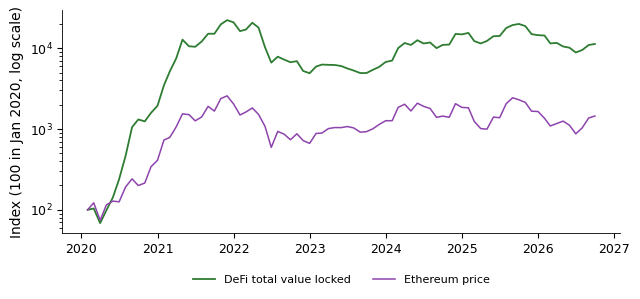

   saved ch16_defi_tvl


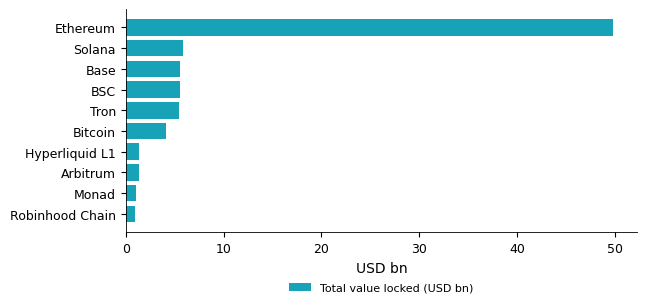

   saved ch16_tvl_chains
{'peak': 177.493346508, 'peak_date': '2021-11-09', 'last': np.float64(88.099591298), 'last_date': '2026-09-18', 'start': np.float64(0.606094144), 'beta': np.float64(0.7895363259188787), 'se': np.float64(0.06574539453618904), 'r2': np.float64(0.6204361240941413), 'n': 80, 'corr': np.float64(0.7876776777934875), 'chains': {'Ethereum': 49.817446769, 'Solana': 5.871750319, 'Base': 5.577350804, 'BSC': 5.571617256, 'Tron': 5.416886891, 'Bitcoin': 4.12670864, 'Hyperliquid L1': 1.373707922, 'Arbitrum': 1.369709319, 'Monad': 1.016054064, 'Robinhood Chain': 0.956868696}, 'eth_share': np.float64(56.54673992810104), 'chains_total': np.float64(88.099591298)}


In [ ]:
print(fig_defi_tvl())

![ch16_defi_tvl](./ch16_defi_tvl.png)

Output: `ch16_defi_tvl.pdf`

![ch16_tvl_chains](./ch16_tvl_chains.png)

Output: `ch16_tvl_chains.pdf`